# PHYTORA · Pipeline B : classification des maladies foliaires
**Dataset :** PlantVillage (Kaggle `abdallahalidev/plantvillage-dataset`, dossier `color`)
**Modèles :** baseline CNN (from scratch) vs MobileNetV3-Small (Transfer Learning en 2 phases)
**Métrique principale :** macro-F1 (classes déséquilibrées), évaluée sur le jeu de **test**

### Pré-requis Kaggle (Settings, panneau de droite)
- **Accelerator : GPU** (T4 ou P100)
- **Internet : On** (téléchargement des poids pré-entraînés de MobileNetV3)
- Le dataset `plantvillage-dataset` doit être ajouté au notebook (*Add Input*)

### Sommaire
1. Configuration
2. Inventaire des données
3. Préparation : dédoublonnage MD5, split stratifié, sauvegarde
4. Datasets et DataLoaders
5. Fonctions d'entraînement et d'évaluation
6. Modèle 1 : baseline CNN
7. Modèle 2 : MobileNetV3 (Transfer Learning)
8. Comparaison, courbes, matrice de confusion
9. Sauvegarde des résultats

> **Démo rapide :** mets `QUICK_RUN = True` dans la cellule 1 (quelques minutes au total). Pour les vrais résultats, laisse `False`.

## 1. Configuration

In [1]:
import os, json, copy, time, random, hashlib, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

# ---------------- Paramètres généraux ----------------
SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = min(4, os.cpu_count() or 2)

QUICK_RUN = False        # True = démo rapide (QUICK_N images max par classe pour train)
QUICK_N = 100
CHECK_IMAGES = True      # vérifie que chaque image s'ouvre (évite un plantage en plein entraînement)

# ---------------- Hyperparamètres ----------------
EPOCHS_BASELINE = 8
EPOCHS_HEAD = 2          # Transfer Learning, phase 1 : tête seule
EPOCHS_FINETUNE = 4      # Transfer Learning, phase 2 : derniers blocs
UNFREEZE_LAST = 3        # nombre de blocs de MobileNetV3 dégelés en phase 2

MEAN = [0.485, 0.456, 0.406]   # statistiques ImageNet
STD = [0.229, 0.224, 0.225]
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

# ---------------- Chemins ----------------
DATA_ROOT = Path("/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color")
if not DATA_ROOT.exists():  # plan B : chercher le dossier "color" dans /kaggle/input
    candidates = [p for p in Path("/kaggle/input").rglob("color") if p.is_dir()]
    if not candidates:
        raise FileNotFoundError("Dossier 'color' introuvable : ajoute le dataset au notebook (Add Input).")
    DATA_ROOT = candidates[0]

WORK_DIR = Path("/kaggle/working")
PROC_DIR = WORK_DIR / "processed"     # CSV + classes.json + summary.json
MODELS_DIR = WORK_DIR / "models"      # checkpoints
RESULTS_DIR = WORK_DIR / "results"    # métriques, courbes, matrices
for d in (PROC_DIR, MODELS_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil     :", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "(pas de GPU !)")
print("Données      :", DATA_ROOT)
print("QUICK_RUN    :", QUICK_RUN)

Appareil     : cuda Tesla T4
Données      : /kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color
QUICK_RUN    : False


## 2. Inventaire des données
Combien de classes ? Combien d'images par classe ? Le déséquilibre est-il fort ?

Classes            : 38
Images au total    : 54305
Minimum / Maximum  : 152 / 5507 (rapport 36 : 1)
Plus petite classe : Potato___healthy
Plus grande classe : Orange___Haunglongbing_(Citrus_greening)


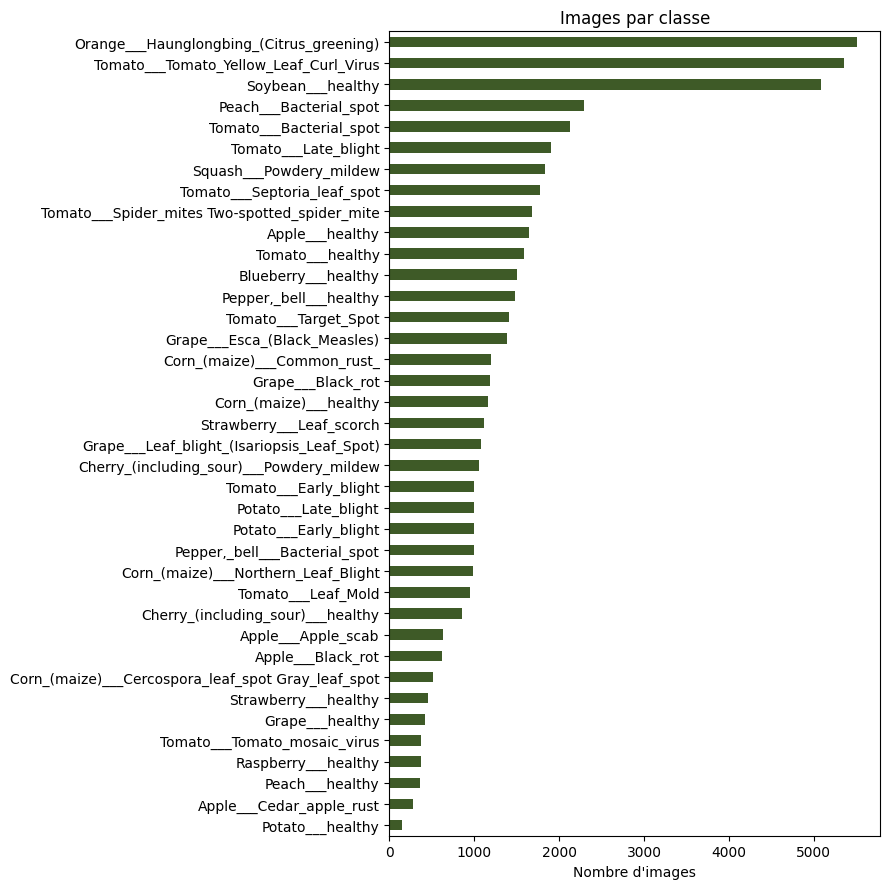

In [3]:
class_dirs = sorted(d for d in DATA_ROOT.iterdir() if d.is_dir())
class_counts = {
    d.name: sum(1 for f in d.iterdir() if f.is_file() and f.suffix.lower() in EXTENSIONS)
    for d in class_dirs
}
inv = pd.Series(class_counts).sort_values()

print("Classes            :", len(inv))
print("Images au total    :", int(inv.sum()))
print("Minimum / Maximum  :", int(inv.min()), "/", int(inv.max()), f"(rapport {inv.max() / inv.min():.0f} : 1)")
print("Plus petite classe :", inv.index[0])
print("Plus grande classe :", inv.index[-1])

fig, ax = plt.subplots(figsize=(9, 9))
inv.plot.barh(ax=ax, color="#3E5A27")
ax.set_xlabel("Nombre d'images")
ax.set_title("Images par classe")
plt.tight_layout()
plt.show()

## 3. Préparation des données
Ordre important pour **éviter toute fuite de données** :
1. lire chaque image (vérification + empreinte **MD5**) ;
2. retirer les contenus à étiquettes contradictoires puis les **doublons exacts** ;
3. **seulement ensuite**, faire le split stratifié 70 / 15 / 15 ;
4. contrôler qu'aucun contenu n'est présent dans deux splits.

Les chemins sont enregistrés **relatifs** à `DATA_ROOT` : les CSV restent utilisables ailleurs (Colab, dépôt, API).

In [4]:
def md5_file(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while True:
            block = f.read(chunk)
            if not block:
                break
            h.update(block)
    return h.hexdigest()


# 1) Lecture + vérification + MD5
records, corrupt = [], []
for class_dir in tqdm(class_dirs, desc="Classes"):
    for p in sorted(class_dir.iterdir()):
        if not (p.is_file() and p.suffix.lower() in EXTENSIONS):
            continue
        if CHECK_IMAGES:
            try:
                with Image.open(p) as im:
                    im.verify()
            except Exception:
                corrupt.append(str(p))
                continue
        records.append({
            "path": str(p.relative_to(DATA_ROOT)),
            "label": class_dir.name,
            "md5": md5_file(p),
        })

df = pd.DataFrame(records)
n_initial = len(df)
print("Images lisibles :", n_initial, "| corrompues écartées :", len(corrupt))

# 2) Contradictions d'étiquettes puis doublons exacts
labels_per_hash = df.groupby("md5")["label"].nunique()
conflict_hashes = set(labels_per_hash[labels_per_hash > 1].index)
n_conflicts = int(df["md5"].isin(conflict_hashes).sum())
df = df[~df["md5"].isin(conflict_hashes)]

n_before = len(df)
df = df.drop_duplicates(subset="md5", keep="first").reset_index(drop=True)
n_duplicates = n_before - len(df)
print("Images à étiquettes contradictoires écartées :", n_conflicts)
print("Doublons exacts retirés                      :", n_duplicates)
print("Images conservées                            :", len(df))

# 3) Classes et indices
CLASSES = sorted(df["label"].unique())
NUM_CLASSES = len(CLASSES)
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
df["class_idx"] = df["label"].map(class_to_idx)
assert df["label"].value_counts().min() >= 10, "Une classe a moins de 10 images."
print("Nombre de classes :", NUM_CLASSES)

# 4) Split stratifié 70 / 15 / 15
train_df, tmp_df = train_test_split(df, test_size=0.30, random_state=SEED, stratify=df["label"])
val_df, test_df = train_test_split(tmp_df, test_size=0.50, random_state=SEED, stratify=tmp_df["label"])

# 5) Contrôle anti-fuite : aucun contenu (MD5) commun à deux splits
s_tr, s_va, s_te = set(train_df["md5"]), set(val_df["md5"]), set(test_df["md5"])
assert not (s_tr & s_va) and not (s_tr & s_te) and not (s_va & s_te), "FUITE : contenu présent dans 2 splits"
print(f"Split -> train {len(train_df)} | val {len(val_df)} | test {len(test_df)}  (aucune fuite MD5)")

Classes:   0%|          | 0/38 [00:00<?, ?it/s]

Images lisibles : 54305 | corrompues écartées : 0
Images à étiquettes contradictoires écartées : 0
Doublons exacts retirés                      : 21
Images conservées                            : 54284
Nombre de classes : 38
Split -> train 37998 | val 8143 | test 8143  (aucune fuite MD5)


In [5]:
# 6) Sauvegarde : CSV (chemins relatifs), classes, résumé
cols = ["path", "label", "class_idx", "md5"]
train_df[cols].to_csv(PROC_DIR / "train.csv", index=False)
val_df[cols].to_csv(PROC_DIR / "val.csv", index=False)
test_df[cols].to_csv(PROC_DIR / "test.csv", index=False)
json.dump(class_to_idx, open(PROC_DIR / "classes.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)

summary = {
    "dataset": "PlantVillage (Kaggle abdallahalidev, dossier color)",
    "seed": SEED,
    "classes": NUM_CLASSES,
    "images_lisibles": n_initial,
    "images_corrompues_ecartees": len(corrupt),
    "images_contradictoires_ecartees": n_conflicts,
    "doublons_exacts_retires": n_duplicates,
    "images_conservees": len(df),
    "train": len(train_df), "val": len(val_df), "test": len(test_df),
    "distribution_par_classe": {k: int(v) for k, v in df["label"].value_counts().items()},
}
json.dump(summary, open(PROC_DIR / "summary.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
print("Fichiers écrits dans", PROC_DIR, ":", sorted(p.name for p in PROC_DIR.iterdir()))

Fichiers écrits dans /kaggle/working/processed : ['classes.json', 'summary.json', 'test.csv', 'train.csv', 'val.csv']


## 4. Datasets et DataLoaders
Les augmentations (recadrage, rotation, **luminosité / contraste**) sont appliquées **uniquement sur train**.
Elles servent à limiter le biais de laboratoire : sur PlantVillage, le fond et la lumière donnent déjà des indices sur la classe.

In [6]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


class PlantVillageDataset(Dataset):
    def __init__(self, dataframe, root, transform=None):
        self.paths = [Path(root) / p for p in dataframe["path"]]
        self.labels = dataframe["class_idx"].astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        image = Image.open(self.paths[i]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, self.labels[i]


def cap_per_class(dataframe, n):
    """Sous-échantillon (démo rapide) : n images max par classe."""
    parts = [g.sample(min(len(g), n), random_state=SEED) for _, g in dataframe.groupby("class_idx")]
    return pd.concat(parts).reset_index(drop=True)


if QUICK_RUN:
    train_used = cap_per_class(train_df, QUICK_N)
    val_used = cap_per_class(val_df, max(10, QUICK_N // 4))
    test_used = cap_per_class(test_df, max(10, QUICK_N // 4))
else:
    train_used, val_used, test_used = train_df, val_df, test_df


def make_loader(dataframe, transform, shuffle):
    return DataLoader(PlantVillageDataset(dataframe, DATA_ROOT, transform), batch_size=BATCH_SIZE,
                      shuffle=shuffle, num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))


train_loader = make_loader(train_used, train_transform, True)
val_loader = make_loader(val_used, eval_transform, False)
test_loader = make_loader(test_used, eval_transform, False)

# Poids de classes (calculés sur train uniquement) contre le déséquilibre
weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_used["class_idx"].values)
class_weights = torch.tensor(weights, dtype=torch.float32, device=DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights)

images, labels = next(iter(train_loader))
print(f"train {len(train_used)} | val {len(val_used)} | test {len(test_used)}")
print("Batch :", tuple(images.shape), tuple(labels.shape), "| classes :", NUM_CLASSES)

train 37998 | val 8143 | test 8143
Batch : (32, 3, 224, 224) (32,) | classes : 38


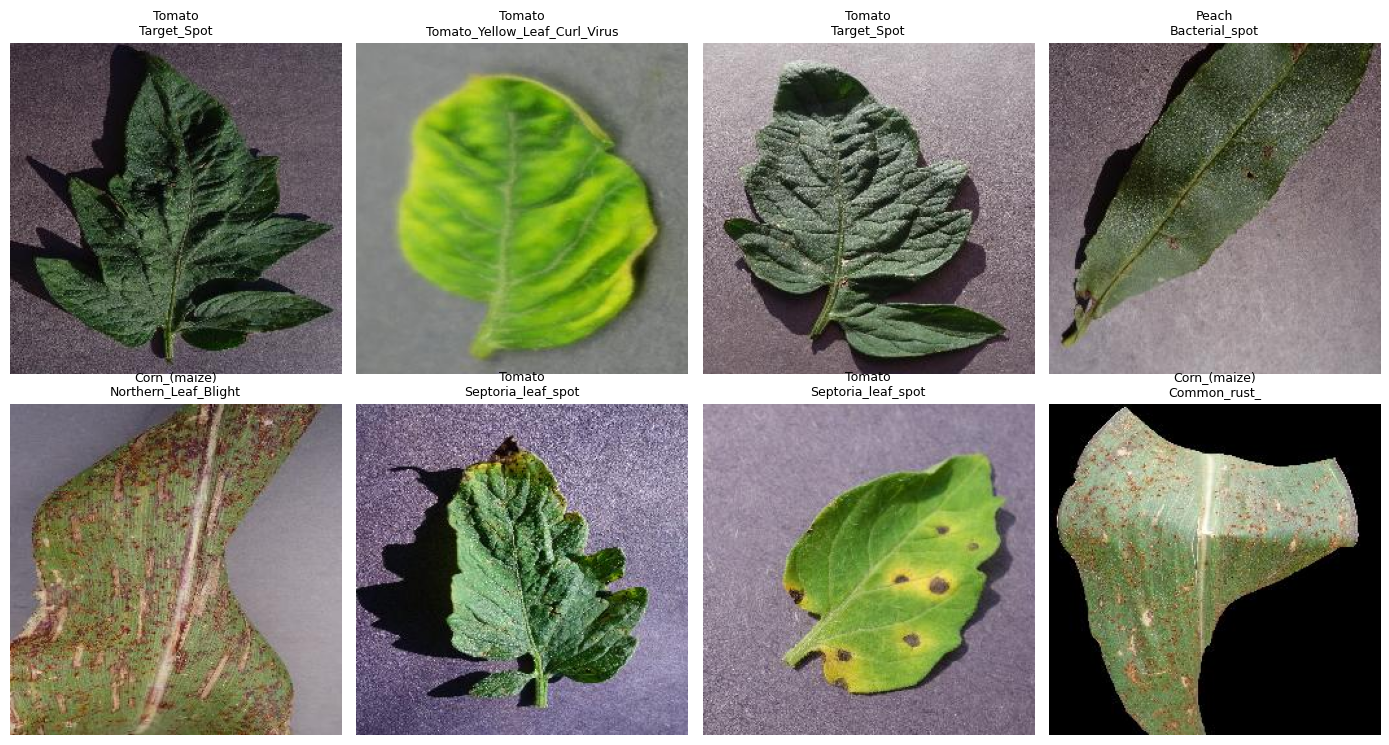

In [7]:
# Aperçu : 8 images de train (sans augmentation) avec leur classe
sample = train_used.sample(8, random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, (_, row) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(Image.open(DATA_ROOT / row["path"]).convert("RGB"))
    ax.set_title(row["label"].replace("___", "\n"), fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Fonctions d'entraînement et d'évaluation
- `run_epoch` : une passe sur un loader (entraînement si un optimiseur est fourni, sinon évaluation).
- `train_model` : enchaîne des **phases** (utile pour le Transfer Learning), garde le **meilleur modèle selon la macro-F1 de validation** et le sauvegarde avec ses métadonnées (classes, taille d'image, normalisation), prêtes pour Grad-CAM, ONNX et l'API.
- `evaluate_test` : évaluation finale **sur le test**, avec rapport par classe et matrice de confusion.

In [9]:
def run_epoch(model, loader, optimizer=None, freeze_bn=False, desc=""):
    training = optimizer is not None
    model.train(training)
    if training and freeze_bn:  # BatchNorm gardées en mode eval : statistiques ImageNet conservées
        for m in model.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.eval()
    total_loss, y_true, y_pred = 0.0, [], []
    with torch.set_grad_enabled(training):
        for images, labels in tqdm(loader, desc=desc, leave=False):
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            loss = criterion(outputs, labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(outputs.argmax(1).cpu().numpy())
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    metrics = {
        "loss": total_loss / len(y_true),
        "acc": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
    }
    return metrics, y_true, y_pred


def train_model(model, model_name, phases):
    """phases : liste de dict(name, epochs, setup(model)->optimizer, freeze_bn)."""
    history, best_f1, best_state, epoch = [], -1.0, None, 0
    ckpt_path = MODELS_DIR / f"{model_name}_best.pt"
    for ph in phases:
        optimizer = ph["setup"](model)
        print(f"\n=== {model_name} | {ph['name']} ({ph['epochs']} époques) ===")
        for _ in range(ph["epochs"]):
            epoch += 1
            t0 = time.time()
            tr, _, _ = run_epoch(model, train_loader, optimizer, ph.get("freeze_bn", False), f"train {epoch}")
            va, _, _ = run_epoch(model, val_loader, desc=f"val {epoch}")
            history.append({"epoch": epoch, "phase": ph["name"],
                            **{f"train_{k}": v for k, v in tr.items()},
                            **{f"val_{k}": v for k, v in va.items()}})
            mark = ""
            if va["macro_f1"] > best_f1:
                best_f1, best_state, mark = va["macro_f1"], copy.deepcopy(model.state_dict()), "  <- meilleur"
                torch.save({"model": model_name, "state_dict": best_state, "classes": CLASSES,
                            "img_size": IMG_SIZE, "mean": MEAN, "std": STD,
                            "best_val_macro_f1": best_f1, "epoch": epoch}, ckpt_path)
            print(f"epoch {epoch:02d} | loss {tr['loss']:.3f}/{va['loss']:.3f} | "
                  f"val acc {va['acc']:.4f} | val macro-F1 {va['macro_f1']:.4f} | {time.time() - t0:.0f}s{mark}")
    model.load_state_dict(best_state)  # on repart du meilleur modèle pour l'évaluation test
    hist = pd.DataFrame(history)
    hist.to_csv(RESULTS_DIR / f"{model_name}_history.csv", index=False)
    return hist, best_f1


def evaluate_test(model):
    metrics, y_true, y_pred = run_epoch(model, test_loader, desc="test")
    labels = list(range(NUM_CLASSES))
    report = classification_report(y_true, y_pred, labels=labels, target_names=CLASSES,
                                   output_dict=True, zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    return metrics, report, cm


results = {}   # rempli après chaque modèle

## 6. Modèle 1 : baseline CNN (from scratch)
Petit CNN à 4 blocs (convolution, BatchNorm, ReLU, pooling). C'est la **référence** : le Transfer Learning devra faire mieux.

In [10]:
def build_baseline(num_classes):
    def block(i, o):
        return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True), nn.MaxPool2d(2))
    return nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 128),
                         nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, num_classes))


set_seed(SEED)
baseline = build_baseline(NUM_CLASSES).to(DEVICE)
print("Paramètres :", sum(p.numel() for p in baseline.parameters()))

hist_base, best_val_base = train_model(baseline, "baseline_cnn", phases=[
    {"name": "baseline", "epochs": EPOCHS_BASELINE, "setup": lambda m: optim.Adam(m.parameters(), lr=1e-3)},
])

Paramètres : 246438

=== baseline_cnn | baseline (8 époques) ===


train 1:   0%|          | 0/1188 [00:00<?, ?it/s]

val 1:   0%|          | 0/255 [00:00<?, ?it/s]

epoch 01 | loss 2.102/1.257 | val acc 0.6396 | val macro-F1 0.5707 | 115s  <- meilleur


train 2:   0%|          | 0/1188 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c1ef1932e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c1ef1932e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (24 outputs left out)

train 8:   0%|          | 0/1188 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c1ef1932e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c1ef1932e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

val 8:   0%|          | 0/255 [00:00<?, ?it/s]

epoch 08 | loss 0.458/0.223 | val acc 0.9282 | val macro-F1 0.9083 | 113s  <- meilleur


In [11]:
m_base, rep_base, cm_base = evaluate_test(baseline)
results["baseline_cnn"] = {"best_val_macro_f1": best_val_base, "test_acc": m_base["acc"],
                           "test_macro_f1": m_base["macro_f1"], "test_loss": m_base["loss"]}
print(f"BASELINE | test accuracy {m_base['acc']:.4f} | test macro-F1 {m_base['macro_f1']:.4f}")

test:   0%|          | 0/255 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c1ef1932e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c1ef1932e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

BASELINE | test accuracy 0.9291 | test macro-F1 0.9096


## 7. Modèle 2 : MobileNetV3-Small (Transfer Learning)
- **Phase 1 (feature extraction)** : base gelée, seule la tête s'entraîne.
- **Phase 2 (fine-tuning)** : les derniers blocs sont dégelés avec un learning rate plus faible.

Les BatchNorm restent en mode évaluation pendant les deux phases (choix de stabilité, à pouvoir justifier à l'oral).

In [12]:
def build_mobilenet(num_classes):
    m = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
    m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, num_classes)
    return m


def setup_head(m):
    for p in m.features.parameters():
        p.requires_grad = False
    for p in m.classifier.parameters():
        p.requires_grad = True
    return optim.Adam(m.classifier.parameters(), lr=1e-3)


def setup_finetune(m):
    for p in m.features[-UNFREEZE_LAST:].parameters():
        p.requires_grad = True
    return optim.Adam([
        {"params": m.features[-UNFREEZE_LAST:].parameters(), "lr": 1e-4},
        {"params": m.classifier.parameters(), "lr": 5e-4},
    ])


set_seed(SEED)
mobilenet = build_mobilenet(NUM_CLASSES).to(DEVICE)

hist_tl, best_val_tl = train_model(mobilenet, "mobilenet_v3_small", phases=[
    {"name": "phase 1 : tête seule", "epochs": EPOCHS_HEAD, "setup": setup_head, "freeze_bn": True},
    {"name": "phase 2 : fine-tuning", "epochs": EPOCHS_FINETUNE, "setup": setup_finetune, "freeze_bn": True},
])

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 137MB/s]


=== mobilenet_v3_small | phase 1 : tête seule (2 époques) ===


train 1:   0%|          | 0/1188 [00:00<?, ?it/s]

val 1:   0%|          | 0/255 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c1ef1932e0><function _MultiProcessingDataLoaderIter.__del__ at 0x79c1ef1932e0>

Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()    
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    
if w.is_alive():  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    if w.is_alive():assert self._parent_pid == os.getpid(), 'can only test a child process'

AssertionError  File "/usr/lib/python3.13/multiprocessing/proce

... (21 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c1ef1932e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
can only test a child processAssertionError: 
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c1ef1932e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

val 6:   0%|          | 0/255 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c1ef1932e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c1ef1932e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

epoch 06 | loss 0.052/0.074 | val acc 0.9840 | val macro-F1 0.9786 | 122s  <- meilleur


In [13]:
m_tl, rep_tl, cm_tl = evaluate_test(mobilenet)
results["mobilenet_v3_small"] = {"best_val_macro_f1": best_val_tl, "test_acc": m_tl["acc"],
                                 "test_macro_f1": m_tl["macro_f1"], "test_loss": m_tl["loss"]}
print(f"MOBILENETV3 | test accuracy {m_tl['acc']:.4f} | test macro-F1 {m_tl['macro_f1']:.4f}")

test:   0%|          | 0/255 [00:00<?, ?it/s]

MOBILENETV3 | test accuracy 0.9834 | test macro-F1 0.9772


## 8. Comparaison et analyse
Tableau comparatif **sur le test**, courbes d'apprentissage, classes les plus faibles et confusions principales.

,best_val_macro_f1,test_acc,test_macro_f1,test_loss
baseline_cnn,0.9083,0.9291,0.9096,0.2219
mobilenet_v3_small,0.9786,0.9834,0.9772,0.0606


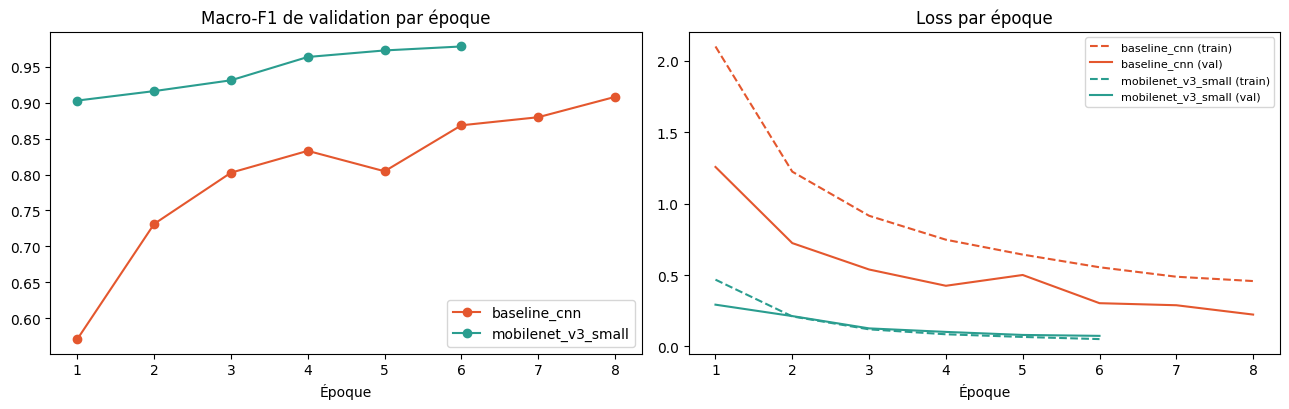

In [14]:
comparison = pd.DataFrame(results).T[["best_val_macro_f1", "test_acc", "test_macro_f1", "test_loss"]]
display(comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for name, h, color in (("baseline_cnn", hist_base, "#E4572E"), ("mobilenet_v3_small", hist_tl, "#2A9D8F")):
    axes[0].plot(h["epoch"], h["val_macro_f1"], marker="o", label=name, color=color)
    axes[1].plot(h["epoch"], h["train_loss"], "--", color=color, label=f"{name} (train)")
    axes[1].plot(h["epoch"], h["val_loss"], "-", color=color, label=f"{name} (val)")
axes[0].set_title("Macro-F1 de validation par époque")
axes[0].set_xlabel("Époque")
axes[0].legend()
axes[1].set_title("Loss par époque")
axes[1].set_xlabel("Époque")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "learning_curves.png", dpi=130)
plt.show()

Analyse d'erreurs sur : mobilenet_v3_small

10 classes au rappel le plus faible :


,rappel
Corn_(maize)___Northern_Leaf_Blight,0.762
Potato___healthy,0.913
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.935
Tomato___Target_Spot,0.938
Tomato___Septoria_leaf_spot,0.951
Tomato___Early_blight,0.960
Peach___Bacterial_spot,0.968
Tomato___Spider_mites Two-spotted_spider_mite,0.972
Tomato___Late_blight,0.975
Apple___Apple_scab,0.979


Confusions les plus fréquentes :


,classe_reelle,classe_predite,nb_images
0,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,34
1,Tomato___Target_Spot,Tomato___Spider_mites Two-spotted_spider_mite,8
2,Tomato___Septoria_leaf_spot,Tomato___Bacterial_spot,6
3,Peach___Bacterial_spot,"Pepper,_bell___Bacterial_spot",5
4,Orange___Haunglongbing_(Citrus_greening),Tomato___Tomato_Yellow_Leaf_Curl_Virus,5
5,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___Target_Spot,5
6,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Corn_(maize)___Northern_Leaf_Blight,4
7,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato___Bacterial_spot,4
8,Tomato___Septoria_leaf_spot,Tomato___Leaf_Mold,4
9,Grape___Esca_(Black_Measles),Grape___Black_rot,4


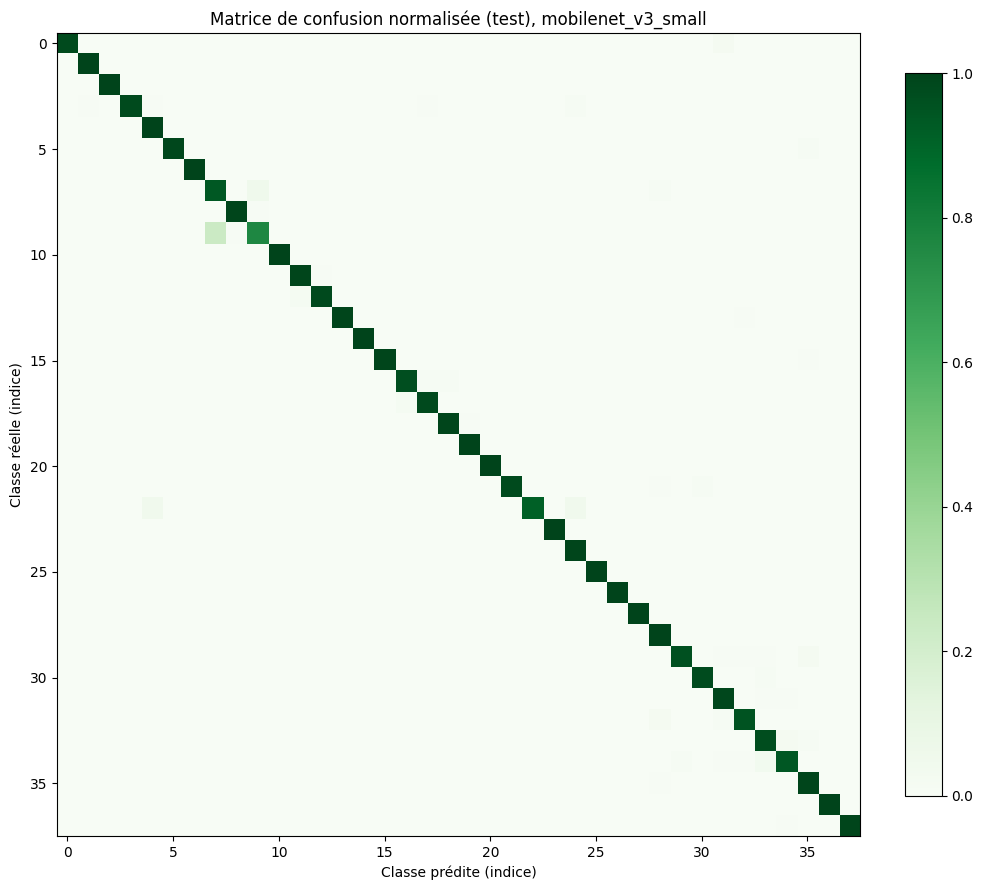

In [15]:
# Meilleur modèle selon la macro-F1 de test (pour l'analyse d'erreurs)
best_name = max(results, key=lambda k: results[k]["test_macro_f1"])
best_report, best_cm = (rep_tl, cm_tl) if best_name == "mobilenet_v3_small" else (rep_base, cm_base)
print("Analyse d'erreurs sur :", best_name)

# Classes les plus faibles (rappel)
recall = pd.Series({c: best_report[c]["recall"] for c in CLASSES}).sort_values()
print("\n10 classes au rappel le plus faible :")
display(recall.head(10).round(3).to_frame("rappel"))


# Confusions principales
def top_confusions(cm, k=10):
    off = cm.copy()
    np.fill_diagonal(off, 0)
    order = np.argsort(off.ravel())[::-1][:k]
    rows = []
    for flat in order:
        i, j = np.unravel_index(flat, off.shape)
        if off[i, j] > 0:
            rows.append((CLASSES[i], CLASSES[j], int(off[i, j])))
    return pd.DataFrame(rows, columns=["classe_reelle", "classe_predite", "nb_images"])


print("Confusions les plus fréquentes :")
display(top_confusions(best_cm))

# Matrice de confusion normalisée par ligne
cm_norm = best_cm / np.maximum(best_cm.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(cm_norm, cmap="Greens", vmin=0, vmax=1)
ax.set_xlabel("Classe prédite (indice)")
ax.set_ylabel("Classe réelle (indice)")
ax.set_title(f"Matrice de confusion normalisée (test), {best_name}")
fig.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=130)
plt.show()

## 9. Sauvegarde des résultats
Tout est regroupé dans une archive `phytora_pipeline_b_outputs.zip` à télécharger (onglet *Output*, ou *Save Version* pour conserver le notebook et ses fichiers).

In [16]:
json.dump(results, open(RESULTS_DIR / "results.json", "w"), indent=2)
json.dump(best_report, open(RESULTS_DIR / f"classification_report_{best_name}.json", "w"), indent=2)
pd.DataFrame(best_cm, index=CLASSES, columns=CLASSES).to_csv(RESULTS_DIR / f"confusion_matrix_{best_name}.csv")
comparison.round(4).to_csv(RESULTS_DIR / "comparison.csv")

bundle = WORK_DIR / "bundle"
bundle.mkdir(exist_ok=True)
for src in (PROC_DIR, MODELS_DIR, RESULTS_DIR):
    shutil.copytree(src, bundle / src.name, dirs_exist_ok=True)
archive = shutil.make_archive(str(WORK_DIR / "phytora_pipeline_b_outputs"), "zip", bundle)
shutil.rmtree(bundle)
print("Archive créée :", archive, f"({Path(archive).stat().st_size / 1e6:.1f} Mo)")
print("\nRésumé :")
display(comparison.round(4))

Archive créée : /kaggle/working/phytora_pipeline_b_outputs.zip (9.8 Mo)

Résumé :


,best_val_macro_f1,test_acc,test_macro_f1,test_loss
baseline_cnn,0.9083,0.9291,0.9096,0.2219
mobilenet_v3_small,0.9786,0.9834,0.9772,0.0606


### Suite du projet
1. Ajouter **Grad-CAM** (vérifier que le modèle regarde la feuille et non le fond) et l'**export ONNX** (`gradcam.py`, `export_onnx.py` du dépôt).
2. Migrer ces cellules vers des scripts dans `src/` (versionnés avec DVC et suivis dans MLflow).
3. Évaluer la généralisation hors laboratoire (photos de feuilles au champ).
4. Passer au pipeline A (YOLO sur CropAndWeed).

**Limite à mentionner dans le rapport :** le MD5 ne retire que les doublons exacts. PlantVillage contient plusieurs photos d'une même feuille, qui peuvent se retrouver dans train et test et gonfler les scores.

In [1]:
import os, json, time, copy, glob, shutil, subprocess, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import accuracy_score, f1_score

SEED = 42
NUM_WORKERS = 2
N_EVAL = 200            # images used for the quantitative Grad-CAM check
FULL_TEST = True        # compare PyTorch vs ONNX on the whole test set (a few minutes)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

rng = np.random.RandomState(SEED)
torch.manual_seed(SEED)


def find_file(name):
    """Look for a file in /kaggle/working then /kaggle/input (skipping the big image folders)."""
    for root in ("/kaggle/working", "/kaggle/input"):
        for dirpath, dirnames, filenames in os.walk(root):
            dirnames[:] = [d for d in dirnames if d not in ("color", "grayscale", "segmented")]
            if name in filenames:
                return Path(dirpath) / name
    raise FileNotFoundError(f"{name} not found: add your training notebook output as an input.")


CKPT = find_file("mobilenet_v3_small_best.pt")
TEST_CSV = find_file("test.csv")
print("Checkpoint :", CKPT)
print("Test CSV   :", TEST_CSV)

DATA_ROOT = Path("/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color")
if not DATA_ROOT.exists():
    candidates = [p for p in Path("/kaggle/input").rglob("color") if p.is_dir()]
    if not candidates:
        raise FileNotFoundError("Folder 'color' not found: add the PlantVillage dataset as an input.")
    DATA_ROOT = candidates[0]
print("Images     :", DATA_ROOT)

WORK = Path("/kaggle/working")
EXPORT_DIR = WORK / "export"
FIG_DIR = WORK / "figures"
for d in (EXPORT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

Device: cuda


FileNotFoundError: mobilenet_v3_small_best.pt not found: add your training notebook output as an input.

In [ ]:
import os, json, time, copy, glob, shutil, subprocess, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import accuracy_score, f1_score

SEED = 42
NUM_WORKERS = 2
N_EVAL = 200            # images used for the quantitative Grad-CAM check
FULL_TEST = True        # compare PyTorch vs ONNX on the whole test set (a few minutes)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

rng = np.random.RandomState(SEED)
torch.manual_seed(SEED)


def find_file(name):
    """Look for a file in /kaggle/working then /kaggle/input (skipping the big image folders)."""
    for root in ("/kaggle/working", "/kaggle/input"):
        for dirpath, dirnames, filenames in os.walk(root):
            dirnames[:] = [d for d in dirnames if d not in ("color", "grayscale", "segmented")]
            if name in filenames:
                return Path(dirpath) / name
    raise FileNotFoundError(f"{name} not found: add your training notebook output as an input.")


CKPT = find_file("mobilenet_v3_small_best.pt")
TEST_CSV = find_file("test.csv")
print("Checkpoint :", CKPT)
print("Test CSV   :", TEST_CSV)

DATA_ROOT = Path("/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color")
if not DATA_ROOT.exists():
    candidates = [p for p in Path("/kaggle/input").rglob("color") if p.is_dir()]
    if not candidates:
        raise FileNotFoundError("Folder 'color' not found: add the PlantVillage dataset as an input.")
    DATA_ROOT = candidates[0]
print("Images     :", DATA_ROOT)

WORK = Path("/kaggle/working")
EXPORT_DIR = WORK / "export"
FIG_DIR = WORK / "figures"
for d in (EXPORT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

In [ ]:
class GradCAM:
    """Grad-CAM on the last convolutional block of MobileNetV3."""

    def __init__(self, net, target_layer):
        self.net = net.eval()
        self.acts, self.grads = None, None
        target_layer.register_forward_hook(self._on_forward)

    def _on_forward(self, module, inputs, output):
        self.acts = output
        output.register_hook(self._on_grad)   # tensor hook: safe with in-place activations

    def _on_grad(self, grad):
        self.grads = grad

    def __call__(self, x, class_idx=None):
        self.net.zero_grad()
        logits = self.net(x)
        if class_idx is None:
            class_idx = int(logits.argmax(1).item())
        logits[0, class_idx].backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((w * self.acts).sum(dim=1, keepdim=True))
        cam = torch.nn.functional.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        prob = float(torch.softmax(logits, 1)[0, class_idx])
        return cam.detach().cpu().numpy(), class_idx, prob


cam_engine = GradCAM(cam_model, cam_model.features[-1])


def explain(img):
    x = eval_transform(img.convert("RGB")).unsqueeze(0).to(DEVICE)
    return cam_engine(x)


def overlay(img, cam, alpha=0.45):
    base = np.asarray(img.convert("RGB").resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32) / 255.0
    heat = matplotlib.colormaps["jet"](cam)[..., :3]
    return np.clip((1 - alpha) * base + alpha * heat, 0, 1)

In [ ]:
# ---- choose ~10 test images: Corn NLB (errors first), Potato healthy, and random ones
def pick(class_name, n_wrong, n_right):
    sub = test_df[test_df["label"] == class_name].reset_index(drop=True)
    if sub.empty:
        print("Class not found:", class_name)
        return sub
    sub["pred"], _ = predict_batch(sub["path"].tolist())
    wrong, right = sub[sub["pred"] != sub["class_idx"]], sub[sub["pred"] == sub["class_idx"]]
    print(f"{class_name}: {len(wrong)} errors / {len(sub)} test images")
    parts = [wrong.sample(min(n_wrong, len(wrong)), random_state=SEED),
             right.sample(min(n_right, len(right)), random_state=SEED)]
    return pd.concat(parts)


corn = pick("Corn_(maize)___Northern_Leaf_Blight", 2, 1).assign(note="Corn NLB")
potato = pick("Potato___healthy", 1, 2).assign(note="Potato healthy")
chosen = pd.concat([corn, potato])
others = test_df[~test_df["path"].isin(chosen["path"])].sample(10 - len(chosen), random_state=SEED).assign(note="random")
sel = pd.concat([chosen, others]).reset_index(drop=True)
print("Selected images:", len(sel))

In [ ]:
n = len(sel)
rows = (n + 1) // 2
fig, axes = plt.subplots(rows, 4, figsize=(15, 3.8 * rows))
axes = np.atleast_2d(axes)
for ax in axes.ravel():
    ax.axis("off")

for i, r in sel.iterrows():
    img = Image.open(DATA_ROOT / r["path"]).convert("RGB")
    cam, pred, prob = explain(img)
    ok = "OK" if pred == r["class_idx"] else "WRONG"
    ax_img, ax_cam = axes[i // 2, (i % 2) * 2], axes[i // 2, (i % 2) * 2 + 1]
    ax_img.imshow(img)
    ax_img.set_title(f"[{r['note']}] {ok}\ntrue: {short(r['label'])}", fontsize=8)
    ax_cam.imshow(overlay(img, cam))
    ax_cam.set_title(f"pred: {short(CLASSES[pred])}\np = {prob:.2f}", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "gradcam_examples.png", dpi=130)
plt.show()

In [ ]:
# ---- Quantitative check (needs the "segmented" folder of the Kaggle dataset, otherwise skipped)
SEG_ROOT = DATA_ROOT.parent / "segmented"


def find_mask(rel_path):
    p = Path(rel_path)
    cls_dir = SEG_ROOT / p.parent
    if not cls_dir.exists():
        return None
    for suffix in ("_final_masked.jpg", "_final_masked.JPG", ".JPG", ".jpg"):
        cand = cls_dir / f"{p.stem}{suffix}"
        if cand.exists():
            return cand
    hits = glob.glob(glob.escape(str(cls_dir / p.stem)) + "*")
    return Path(hits[0]) if hits else None


records = []
for _, r in tqdm(test_df.sample(min(N_EVAL, len(test_df)), random_state=SEED).iterrows(), total=min(N_EVAL, len(test_df))):
    mp = find_mask(r["path"])
    if mp is None:
        continue
    img = Image.open(DATA_ROOT / r["path"]).convert("RGB")
    mask = np.asarray(Image.open(mp).convert("L").resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)) > 10
    area = float(mask.mean())
    if area < 0.02:
        continue
    cam, pred, prob = explain(img)
    records.append({"correct": pred == r["class_idx"], "leaf_area_share": area,
                    "cam_share_on_leaf": float(cam[mask].sum() / (cam.sum() + 1e-8))})

if not records:
    print("No segmented masks found: quantitative check skipped (visual check above still applies).")
else:
    q = pd.DataFrame(records)
    q["focus_ratio"] = q["cam_share_on_leaf"] / q["leaf_area_share"]
    print(f"Images analysed: {len(q)}")
    summary = pd.DataFrame({
        "leaf area share (chance level)": [q["leaf_area_share"].mean()],
        "Grad-CAM share on leaf": [q["cam_share_on_leaf"].mean()],
        "focus ratio (>1 = focuses on leaf)": [q["focus_ratio"].mean()],
        "% images with ratio > 1": [100 * (q["focus_ratio"] > 1).mean()],
    }).round(3)
    display(summary)
    display(q.groupby("correct")[["cam_share_on_leaf", "focus_ratio"]].mean().round(3))
    q.to_csv(FIG_DIR / "gradcam_leaf_focus.csv", index=False)

In [ ]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "onnx", "onnxruntime", "onnxscript"], check=False)
import onnx
import onnxruntime as ort
print("torch", torch.__version__, "| onnx", onnx.__version__, "| onnxruntime", ort.__version__)

In [ ]:
export_model = load_model().cpu()          # fresh, clean copy (no Grad-CAM hooks)
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
ONNX_PATH = EXPORT_DIR / "model.onnx"
OPSET = 17


def export_to_onnx():
    kwargs = dict(input_names=["input"], output_names=["logits"],
                  dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}}, opset_version=OPSET)
    for extra in ({"dynamo": False}, {}):   # classic exporter first, then the default one
        try:
            torch.onnx.export(export_model, dummy, str(ONNX_PATH), **kwargs, **extra)
            return extra
        except Exception as e:
            print(f"Export attempt {extra} failed: {type(e).__name__}: {str(e)[:200]}")
    raise RuntimeError("ONNX export failed with both exporters")


used = export_to_onnx()
onnx.checker.check_model(onnx.load(str(ONNX_PATH)))
print(f"Exported {ONNX_PATH.name} ({ONNX_PATH.stat().st_size / 1e6:.1f} MB), exporter options: {used or 'default'}; checker OK")

In [ ]:
# ---- Parity check on 32 real test images
sess = ort.InferenceSession(str(ONNX_PATH), providers=["CPUExecutionProvider"])
batch_paths = test_df.sample(32, random_state=SEED)["path"].tolist()
x = torch.stack([eval_transform(Image.open(DATA_ROOT / p).convert("RGB")) for p in batch_paths])
with torch.no_grad():
    ref = export_model(x).numpy()
got = sess.run(None, {"input": x.numpy()})[0]

max_diff = float(np.abs(ref - got).max())
same_top1 = bool((ref.argmax(1) == got.argmax(1)).all())
print(f"Max |logit difference| PyTorch vs ONNX : {max_diff:.2e}")
print(f"Same predicted class on all 32 images  : {same_top1}")
assert max_diff < 1e-3 and same_top1, "ONNX export is not faithful to the PyTorch model"

# batch axis really dynamic?
print("Batch of 1 ->", sess.run(None, {"input": x[:1].numpy()})[0].shape, "| batch of 8 ->", sess.run(None, {"input": x[:8].numpy()})[0].shape)

In [ ]:
# ---- CPU latency, single image
def bench(fn, n=100, warmup=10):
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(n):
        t0 = time.perf_counter()
        fn()
        times.append((time.perf_counter() - t0) * 1000)
    return {"mean_ms": float(np.mean(times)), "p95_ms": float(np.percentile(times, 95))}


x1 = x[:1]
with torch.no_grad():
    lat_torch = bench(lambda: export_model(x1))
lat_onnx = bench(lambda: sess.run(None, {"input": x1.numpy()}))
print(f"CPU ({os.cpu_count()} cores) | PyTorch: {lat_torch['mean_ms']:.1f} ms (p95 {lat_torch['p95_ms']:.1f}) | "
      f"ONNX Runtime: {lat_onnx['mean_ms']:.1f} ms (p95 {lat_onnx['p95_ms']:.1f})")
print("Model inference only: add preprocessing (decode + resize) for the end-to-end API latency.")

In [ ]:
# ---- Whole test set: PyTorch (GPU/CPU) vs ONNX Runtime
class TestDataset(Dataset):
    def __init__(self, df):
        self.paths, self.y = df["path"].tolist(), df["class_idx"].astype(int).tolist()

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return eval_transform(Image.open(DATA_ROOT / self.paths[i]).convert("RGB")), self.y[i]


full = {}
if FULL_TEST:
    loader = DataLoader(TestDataset(test_df), batch_size=64, shuffle=False, num_workers=NUM_WORKERS)
    y_true, p_torch, p_onnx = [], [], []
    with torch.no_grad():
        for xb, yb in tqdm(loader, desc="test set"):
            p_torch.append(model(xb.to(DEVICE)).argmax(1).cpu().numpy())
            p_onnx.append(sess.run(None, {"input": xb.numpy()})[0].argmax(1))
            y_true.append(yb.numpy())
    y_true, p_torch, p_onnx = map(np.concatenate, (y_true, p_torch, p_onnx))
    full = {
        "images": int(len(y_true)),
        "pytorch_acc": float(accuracy_score(y_true, p_torch)),
        "pytorch_macro_f1": float(f1_score(y_true, p_torch, average="macro", zero_division=0)),
        "onnx_acc": float(accuracy_score(y_true, p_onnx)),
        "onnx_macro_f1": float(f1_score(y_true, p_onnx, average="macro", zero_division=0)),
        "prediction_agreement": float((p_torch == p_onnx).mean()),
    }
    display(pd.Series(full).round(5).to_frame("value"))

In [ ]:
REFERENCE_PY = '"""\nPHYTORA - Pipeline B : reference inference with ONNX Runtime.\n\nCopy this logic into backend/app/inference.py. Preprocessing is IDENTICAL to training:\nRGB -> PIL bilinear resize -> /255 -> (x - mean) / std -> NCHW float32.\nThe model outputs logits: softmax is applied here.\n"""\nimport json\nfrom pathlib import Path\n\nimport numpy as np\nimport onnxruntime as ort\nfrom PIL import Image\n\n\nclass DiseaseClassifier:\n    def __init__(self, model_dir):\n        d = Path(model_dir)\n        self.session = ort.InferenceSession(str(d / "model.onnx"), providers=["CPUExecutionProvider"])\n        cfg = json.load(open(d / "preprocess.json", encoding="utf-8"))\n        class_to_idx = json.load(open(d / "classes.json", encoding="utf-8"))\n        self.classes = [c for c, _ in sorted(class_to_idx.items(), key=lambda kv: kv[1])]\n        self.size = tuple(cfg["resize"])\n        self.mean = np.array(cfg["mean"], dtype=np.float32).reshape(1, 1, 3)\n        self.std = np.array(cfg["std"], dtype=np.float32).reshape(1, 1, 3)\n        self.input_name = cfg["input_name"]\n\n    def preprocess(self, image):\n        img = image.convert("RGB").resize(self.size, Image.BILINEAR)\n        arr = (np.asarray(img, dtype=np.float32) / 255.0 - self.mean) / self.std\n        return arr.transpose(2, 0, 1)[None].astype(np.float32)\n\n    def predict(self, image, top_k=5):\n        logits = self.session.run(None, {self.input_name: self.preprocess(image)})[0][0]\n        e = np.exp(logits - logits.max())\n        probs = e / e.sum()\n        order = probs.argsort()[::-1][:top_k]\n        return [{"label": self.classes[i], "score": float(probs[i])} for i in order]\n'

json.dump({c: i for i, c in enumerate(CLASSES)}, open(EXPORT_DIR / "classes.json", "w", encoding="utf-8"),
          indent=2, ensure_ascii=False)
json.dump({
    "model": ckpt["model"], "onnx_opset": OPSET,
    "input_name": "input", "output_name": "logits",
    "input_shape": ["batch", 3, IMG_SIZE, IMG_SIZE], "dtype": "float32", "layout": "NCHW",
    "channel_order": "RGB", "resize": [IMG_SIZE, IMG_SIZE], "resize_method": "PIL bilinear",
    "scale": "pixels / 255.0", "mean": MEAN, "std": STD,
    "output": "logits (one per class, order = classes.json); apply softmax in the API",
    "num_classes": NUM_CLASSES,
}, open(EXPORT_DIR / "preprocess.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
open(EXPORT_DIR / "reference_inference.py", "w", encoding="utf-8").write(REFERENCE_PY)
print("Written:", sorted(p.name for p in EXPORT_DIR.iterdir()))

In [ ]:
# ---- Verify the reference inference code against PyTorch on 20 test images
import importlib.util
spec = importlib.util.spec_from_file_location("reference_inference", EXPORT_DIR / "reference_inference.py")
ref_mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(ref_mod)
clf = ref_mod.DiseaseClassifier(EXPORT_DIR)

paths = test_df.sample(20, random_state=1)["path"].tolist()
max_prob_diff, agree = 0.0, 0
for p in paths:
    img = Image.open(DATA_ROOT / p)
    top = clf.predict(img, top_k=1)[0]
    with torch.no_grad():
        probs = torch.softmax(export_model(eval_transform(img.convert("RGB")).unsqueeze(0)), 1)[0]
    max_prob_diff = max(max_prob_diff, abs(top["score"] - float(probs.max())))
    agree += int(top["label"] == CLASSES[int(probs.argmax())])
print(f"reference_inference.py vs PyTorch: same class on {agree}/20 images | max |prob difference| = {max_prob_diff:.2e}")
assert agree == 20 and max_prob_diff < 1e-3

print("\nExample output for the API:")
print(json.dumps(clf.predict(Image.open(DATA_ROOT / paths[0]), top_k=3), indent=2))

In [ ]:
report = {
    "model": ckpt["model"], "classes": NUM_CLASSES, "onnx_opset": OPSET,
    "onnx_size_mb": round(ONNX_PATH.stat().st_size / 1e6, 2),
    "parity": {"max_abs_logit_diff": max_diff, "same_top1_on_32_images": same_top1},
    "cpu_latency_single_image_ms": {"pytorch": lat_torch, "onnxruntime": lat_onnx, "cpu_cores": os.cpu_count()},
    "full_test_set": full,
    "versions": {"torch": torch.__version__, "onnx": onnx.__version__, "onnxruntime": ort.__version__},
}
json.dump(report, open(EXPORT_DIR / "export_report.json", "w"), indent=2)

bundle = WORK / "bundle"
bundle.mkdir(exist_ok=True)
shutil.copytree(EXPORT_DIR, bundle / "export", dirs_exist_ok=True)
shutil.copytree(FIG_DIR, bundle / "figures", dirs_exist_ok=True)
archive = shutil.make_archive(str(WORK / "phytora_pipeline_b_export"), "zip", bundle)
shutil.rmtree(bundle)
print("Archive:", archive, f"({Path(archive).stat().st_size / 1e6:.1f} MB)")
print(json.dumps(report, indent=2))